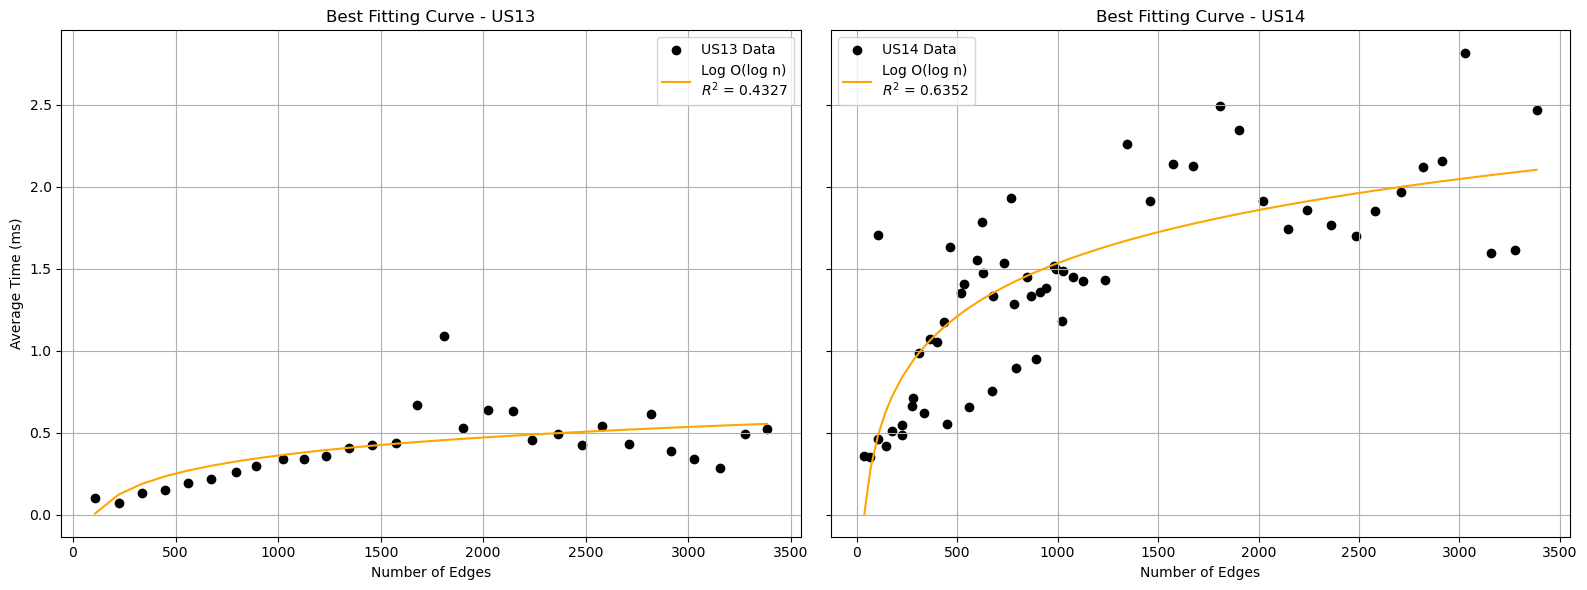

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load CSV files with benchmark results for US13 and US14
data13 = pd.read_csv("us13_results_us30.csv", sep=";", decimal=",")
data14 = pd.read_csv("us14_results_us30.csv", sep=";", decimal=",")
    
# Define a function to determine the best curve fit among common complexity classes
def best_fit(x, y):
    # Define candidate complexity models with transformations applied to x
    models = {
        "Linear O(n)": x,
        "Log O(log n)": np.log(x),
        "Linearithmic O(n log n)": x * np.log(x),
        "Quadratic O(n²)": x**2,
        "Cubic O(n³)": x**3
    }

    # Initialize variables to store the best model
    best_r2 = -np.inf  # Best R-squared score
    best_fit_line = None  # Best y-values (fitted line)
    best_label = ""  # Label for legend
    best_color = "blue"  # Color for plotting
    colors = ["blue", "orange", "green", "red", "purple"]  # Colors for each model

    # Try each model and calculate the R-squared to find the best fit
    for (label, x_trans), color in zip(models.items(), colors):
        # Compute simple linear regression coefficients: y = beta0 + beta1 * x
        x_mean = np.mean(x_trans)
        y_mean = np.mean(y)
        Sxx = np.sum((x_trans - x_mean) ** 2)
        Sxy = np.sum((x_trans - x_mean) * (y - y_mean))
        beta1 = Sxy / Sxx
        beta0 = y_mean - beta1 * x_mean
        y_fit = beta0 + beta1 * x_trans  # Predicted y values

        # Calculate R-squared score
        ss_tot = np.sum((y - y_mean) ** 2)
        ss_res = np.sum((y - y_fit) ** 2)
        r2 = 1 - ss_res / ss_tot

        # Update best fit if this model has a better R-squared
        if r2 > best_r2:
            best_r2 = r2
            best_fit_line = y_fit
            best_label = f"{label}\n$R^2$ = {r2:.4f}"
            best_color = color

    return best_fit_line, best_label, best_color

# Prepare average data for US13: group by number of edges and compute mean time
group13 = data13.groupby("size")["time"].mean().reset_index()
x13 = group13["size"].values
y13 = group13["time"].values

# Prepare average data for US14: same procedure
group14 = data14.groupby("size")["time"].mean().reset_index()
x14 = group14["size"].values
y14 = group14["time"].values

# Compute the best fit curves for both datasets
fit13, label13, color13 = best_fit(x13, y13)
fit14, label14, color14 = best_fit(x14, y14)

# Create two side-by-side subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

# Plot US13 data
ax1.scatter(x13, y13, color="black", label="US13 Data")  # Scatter plot of raw data
ax1.plot(x13, fit13, color=color13, label=label13)       # Best fitting curve
ax1.set_title("Best Fitting Curve - US13")
ax1.set_xlabel("Number of Edges")
ax1.set_ylabel("Average Time (ms)")
ax1.grid(True)
ax1.legend()

# Plot US14 data
ax2.scatter(x14, y14, color="black", label="US14 Data")  # Scatter plot of raw data
ax2.plot(x14, fit14, color=color14, label=label14)       # Best fitting curve
ax2.set_title("Best Fitting Curve - US14")
ax2.set_xlabel("Number of Edges")
ax2.grid(True)
ax2.legend()

# Adjust layout and display the plot
plt.tight_layout()
plt.show()

In [2]:
import pandas as pd
import numpy as np
from scipy import stats

#reads csv file
data = pd.read_csv('Stations_Data.csv', sep= ';')

#display available stations for user to choose from
availableStations = data['Station'].unique()
print(f'Available Stations:')
for i, station in enumerate(sorted(availableStations), 1):
    print(f'{i:2d}. {station}')

#display available years for user to choose from
availableYears = data['Year'].unique()
print(f'\nAvailable Years:')
for j, year, in enumerate(sorted(availableYears), 1):
    print(f'{j:2d}. {year}')

#user input
station = int(input('\nChoose a station from the list (enter the correspondant number): '))
year = int(input('Choose a year from the list (enter the correspondant number): '))

#display either error message or recap of user's choices
if not (1 <= station <= len(sorted(availableStations))) or not (1 <= year <= len(sorted(availableYears))):
    print('Invalid option.')
else: 
    chosenStation = sorted(availableStations)[station - 1]
    chosenYear = sorted(availableYears)[year - 1]
    print(f'\n\nYou have chosen station "{chosenStation}" in {chosenYear}.')

#organize the document info in a revenue column
columns = ['Iron', 'Coal', 'Steel', 'Vegetables', 'Cereals', 'Wool', 'Coffee', 'Cattle', 'Revenues']

#convert values to either string or NaN if they're not numeric by replacing comma decimal seperators with dots for proper numeric convertion
for col in columns:
    data[col] = pd.to_numeric(data[col].astype(str).str.replace(',', '.', regex=False), errors='coerce')

#filter data for chosen year and station 
filtered = data[(data['Station'] == chosenStation) & (data['Year'] == chosenYear)]

#definition of cargo types and revenue
cargoTypes = ['Iron', 'Coal', 'Steel', 'Vegetables', 'Cereals', 'Wool', 'Coffee', 'Cattle']

#find correlations and best cargo
correlations = filtered[cargoTypes + ['Revenues']].corr()['Revenues'].drop('Revenues')
best_cargo = correlations.abs().idxmax()
correlation_value = correlations[best_cargo]

print(f'\n\nCargo with the best correlation and revenue: {best_cargo}.')
print(f'Correlation: {correlation_value:.4f}')

#linear regression through minimal squares
x = filtered[best_cargo].values
y = filtered['Revenues'].values
n = len(x)
x_mean = np.mean(x)
y_mean = np.mean(y)
Sxx = np.sum((x - x_mean)**2)
Sxy = np.sum((x - x_mean) * (y - y_mean))
beta1 = Sxy / Sxx
beta0 = y_mean - beta1 * x_mean

print(f'\nLinear regression equation for "{chosenStation}" in {chosenYear}: y = {beta0:.2f} + {beta1:.2f}x')

#forecast of revenue for january with +10%
x_jan = filtered.loc[filtered['Month'] == 1, best_cargo].mean()
xp = x_jan * 1.10
y_hat = beta0 + beta1 * xp

#calculation of error and precision range
y_pred = beta0 + beta1 * x
sqe = np.sum((y - y_pred)**2)
s2 = sqe / (n - 2)

#precision range of 95%
t_val = stats.t.ppf(0.975, df=n - 2)
margin_error = t_val * np.sqrt(s2 * (1 + 1/n + ((xp - x_mean)**2) / Sxx))
lower = y_hat - margin_error
upper = y_hat + margin_error

print(f'\nEstimated revenue for January {chosenYear + 1} (with +10% of {best_cargo}): {y_hat:.2f}€')
print(f'Precision range 95%: [{lower:.2f}, {upper:.2f}]')

# AUTOMATIC RESULTS INTERPRETATION
print("\n\n" + "="*60)
print("RESULTS INTERPRETATION")
print("="*60)

# Correlation strength analysis
def interpret_correlation(r):
    abs_r = abs(r)
    if abs_r >= 0.8:
        return "very strong", "excellent predictor"
    elif abs_r >= 0.6:
        return "strong", "good predictor"
    elif abs_r >= 0.4:
        return "moderate", "reasonable predictor"
    elif abs_r >= 0.2:
        return "weak", "poor predictor"
    else:
        return "very weak", "very poor predictor"

strength, predictor_quality = interpret_correlation(correlation_value)
r_squared = correlation_value**2

print(f"\n1. CORRELATION ANALYSIS:")
print(f"   • {best_cargo} shows a {strength} {'positive' if correlation_value > 0 else 'negative'} correlation with revenue")
print(f"   • Correlation coefficient: {correlation_value:.4f}")
print(f"   • R²: {r_squared:.3f} ({r_squared*100:.1f}% of revenue variation explained)")
print(f"   • Assessment: {best_cargo} is a {predictor_quality} of station revenue")

print(f"\n2. LINEAR REGRESSION MODEL:")
print(f"   • Equation: Revenue = {beta0:.2f} + {beta1:.2f} × {best_cargo}")
print(f"   • Base revenue (when {best_cargo} = 0): {beta0:.2f}€")
print(f"   • Revenue per unit of {best_cargo}: {beta1:.2f}€")
if beta1 > 0:
    print(f"   • Economic meaning: Each additional unit of {best_cargo} increases revenue by {beta1:.2f}€")
else:
    print(f"   • Economic meaning: Each additional unit of {best_cargo} decreases revenue by {abs(beta1):.2f}€")

print(f"\n3. JANUARY FORECAST ANALYSIS:")
print(f"   • Baseline January {best_cargo} volume: {x_jan:.2f} units")
print(f"   • Projected volume (+10%): {xp:.2f} units")
print(f"   • Expected revenue: {y_hat:.2f}€")
confidence_width = upper - lower
print(f"   • Confidence interval width: {confidence_width:.2f}€")
print(f"   • Uncertainty level: ±{(confidence_width/2/y_hat)*100:.1f}% of predicted value")

Available Stations:
 1. Berlin
 2. Frankfurt
 3. Hamburg
 4. Hannover
 5. Stuttgart

Available Years:
 1. 2015
 2. 2016
 3. 2017
 4. 2018
 5. 2019
 6. 2020
 7. 2021
 8. 2022
 9. 2023
10. 2024



Choose a station from the list (enter the correspondant number):  4
Choose a year from the list (enter the correspondant number):  6




You have chosen station "Hannover" in 2020.


Cargo with the best correlation and revenue: Coal.
Correlation: 0.9805

Linear regression equation for "Hannover" in 2020: y = 93.16 + 21.54x

Estimated revenue for January 2021 (with +10% of Coal): 676.87€
Precision range 95%: [570.40, 783.33]


RESULTS INTERPRETATION

1. CORRELATION ANALYSIS:
   • Coal shows a very strong positive correlation with revenue
   • Correlation coefficient: 0.9805
   • R²: 0.961 (96.1% of revenue variation explained)
   • Assessment: Coal is a excellent predictor of station revenue

2. LINEAR REGRESSION MODEL:
   • Equation: Revenue = 93.16 + 21.54 × Coal
   • Base revenue (when Coal = 0): 93.16€
   • Revenue per unit of Coal: 21.54€
   • Economic meaning: Each additional unit of Coal increases revenue by 21.54€

3. JANUARY FORECAST ANALYSIS:
   • Baseline January Coal volume: 24.64 units
   • Projected volume (+10%): 27.10 units
   • Expected revenue: 676.87€
   • Confidence interval width: 212.92€
   • Unce